## Part A - Image Representation 


In [24]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import train_test_split

np.random.seed(42)

In [25]:
DATASET_DIR = Path("C:/Users/Admin/Desktop/Fundaments of ML DS605/ML_LAB7/Data")

subject_folders = sorted(
    [p for p in DATASET_DIR.iterdir()
     if p.is_dir() and p.name.startswith("s")
     and p.name[1:].isdigit()],
    key=lambda p: int(p.name[1:])
)

print("Dataset folder:", DATASET_DIR.resolve())
print("Number of subjects:", len(subject_folders))

if len(subject_folders) == 0:
    raise FileNotFoundError("Check your dataset folder path.")

Dataset folder: C:\Users\Admin\Desktop\Fundaments of ML DS605\ML_LAB7\Data
Number of subjects: 40


Image dimensions: (112, 92)
Data type: uint8
Minimum intensity: 11
Maximum intensity: 234
First 10 pixel values: [48 49 45 47 49 57 39 42 53 49]


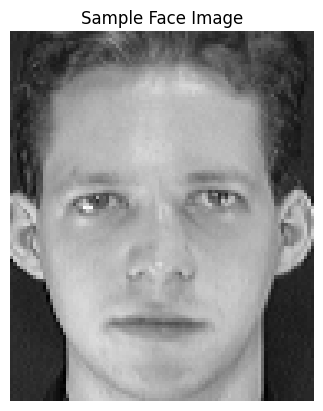

In [26]:
sample_file = sorted(subject_folders[0].glob("*.pgm"))[0]

sample_image = np.array(
    Image.open(sample_file).convert("L")
)

print("Image dimensions:", sample_image.shape)
print("Data type:", sample_image.dtype)
print("Minimum intensity:", sample_image.min())
print("Maximum intensity:", sample_image.max())
print("First 10 pixel values:", sample_image.flatten()[:10])

plt.imshow(sample_image, cmap="gray")
plt.title("Sample Face Image")
plt.axis("off")
plt.show()

In [27]:
images = []
labels = []
for folder in subject_folders:
    files = sorted(
        folder.glob("*.pgm"),
        key=lambda p: int(p.stem)
    )

    for file in files:
        image = np.array(
            Image.open(file).convert("L")
        )

        images.append(image.flatten())
        labels.append(int(folder.name[1:]))

X = np.array(images, dtype=np.uint8)
y = np.array(labels)

print("Feature matrix shape:", X.shape)
print("Labels shape:", y.shape)
print("Unique subjects:", len(np.unique(y)))
print("Images per subject:", np.unique(y, return_counts=True)[1])
print("First image feature vector:", X[0])

Feature matrix shape: (400, 10304)
Labels shape: (400,)
Unique subjects: 40
Images per subject: [10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10
 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10]
First image feature vector: [48 49 45 ... 47 46 46]


In [28]:
indices = np.arange(len(y))

train_idx, test_idx = train_test_split(
    indices,
    test_size=0.20,
    random_state=42,
    stratify=y
)

X_train = X[train_idx]
X_test = X[test_idx]

y_train = y[train_idx]
y_test = y[test_idx]

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)
print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

Training data: (320, 10304)
Testing data: (80, 10304)
Training labels: (320,)
Testing labels: (80,)


In [29]:
print("Subjects in training:", len(np.unique(y_train)))
print("Subjects in testing:", len(np.unique(y_test)))

print("Training images per subject:",
      np.unique(y_train, return_counts=True)[1])

print("Testing images per subject:",
      np.unique(y_test, return_counts=True)[1])

assert set(y_train) == set(y)
assert set(y_test) == set(y)

print("Success: Every subject appears in both sets.")

Subjects in training: 40
Subjects in testing: 40
Training images per subject: [8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8
 8 8 8]
Testing images per subject: [2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2]
Success: Every subject appears in both sets.


## Part B - PCA, Eigenfaces and Compression 


In [30]:
import numpy as np
import matplotlib.pyplot as plt

X_train_float = X_train.astype(float)
X_test_float = X_test.astype(float)

image_height, image_width = sample_image.shape

print("Training data shape:", X_train_float.shape)
print("Testing data shape:", X_test_float.shape)
print("Image dimensions:", image_height, image_width)

Training data shape: (320, 10304)
Testing data shape: (80, 10304)
Image dimensions: 112 92


Mean face shape: (10304,)
Covariance matrix shape: (320, 320)
Number of valid components: 319


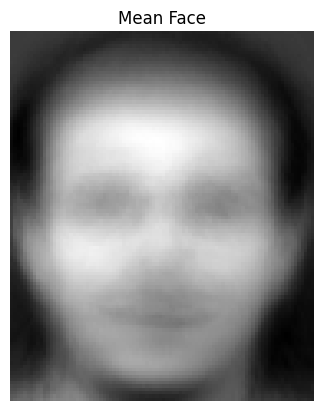

In [31]:
# Compute the mean face using training images only
mean_face = np.mean(X_train_float, axis=0)

# Center the training data
X_centered = X_train_float - mean_face

# Covariance method using the smaller sample-space matrix
cov_matrix = (X_centered @ X_centered.T) / (len(X_centered) - 1)

eigenvalues, eigenvectors = np.linalg.eigh(cov_matrix)

# Sort eigenvalues and eigenvectors in descending order
order = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[order]
eigenvectors = eigenvectors[:, order]

# Remove numerical zero eigenvalues
valid = eigenvalues > eigenvalues[0] * 1e-10
eigenvalues = eigenvalues[valid]
eigenvectors = eigenvectors[:, valid]

# Convert sample-space eigenvectors into pixel-space eigenfaces
components_cov = X_centered.T @ eigenvectors
components_cov = components_cov / np.sqrt(
    (len(X_centered) - 1) * eigenvalues
)

print("Mean face shape:", mean_face.shape)
print("Covariance matrix shape:", cov_matrix.shape)
print("Number of valid components:", len(eigenvalues))

plt.imshow(mean_face.reshape(image_height, image_width), cmap="gray")
plt.title("Mean Face")
plt.axis("off")
plt.show()

In [32]:
# Perform Singular Value Decomposition
U, singular_values, Vt = np.linalg.svd(
    X_centered, full_matrices=False
)

# Remove numerical zero singular values
valid_svd = singular_values > singular_values[0] * 1e-10
singular_values = singular_values[valid_svd]
components_svd = Vt[valid_svd]

# Explained variance from both methods
variance_cov = eigenvalues / np.sum(eigenvalues)
variance_svd = singular_values**2 / np.sum(singular_values**2)

print("Covariance components:", components_cov.shape)
print("SVD components:", components_svd.shape)

# Compare the first 10 corresponding principal directions
number_to_compare = min(10, len(components_cov), len(components_svd))
similarities = np.abs(
    np.sum(
        components_cov[:, :number_to_compare].T
        * components_svd[:number_to_compare],
        axis=1
    )
)

print("Absolute cosine similarities of first components:")
print(similarities)

print("Maximum explained-variance difference:",
      np.max(np.abs(variance_cov - variance_svd)))

Covariance components: (10304, 319)
SVD components: (319, 10304)
Absolute cosine similarities of first components:
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
Maximum explained-variance difference: 2.498001805406602e-16


Components required for 90% variance: 98
Variance preserved: 0.9005854818500819


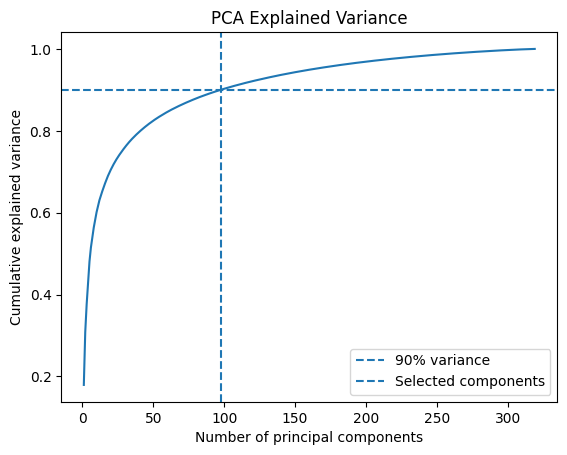

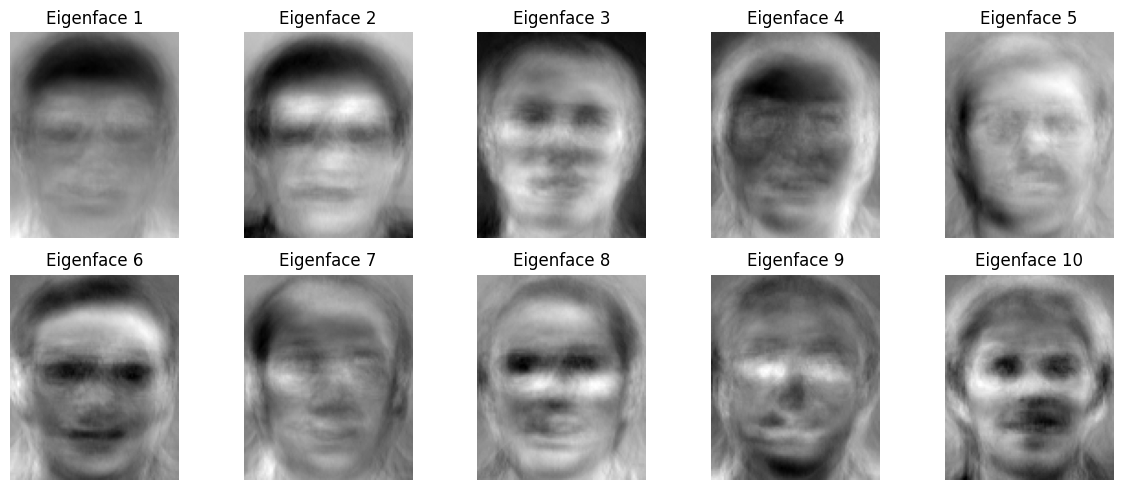

In [33]:
# Cumulative explained variance using SVD
cumulative_variance = np.cumsum(variance_svd)

# Minimum number of components needed for 90% variance
k = np.searchsorted(cumulative_variance, 0.90) + 1

print("Components required for 90% variance:", k)
print("Variance preserved:", cumulative_variance[k - 1])

plt.plot(
    np.arange(1, len(cumulative_variance) + 1),
    cumulative_variance
)
plt.axhline(y=0.90, linestyle="--", label="90% variance")
plt.axvline(x=k, linestyle="--", label="Selected components")
plt.xlabel("Number of principal components")
plt.ylabel("Cumulative explained variance")
plt.title("PCA Explained Variance")
plt.legend()
plt.show()

# Display the first 10 eigenfaces
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    ax.imshow(
        components_svd[i].reshape(image_height, image_width),
        cmap="gray"
    )
    ax.set_title("Eigenface " + str(i + 1))
    ax.axis("off")

plt.tight_layout()
plt.show()

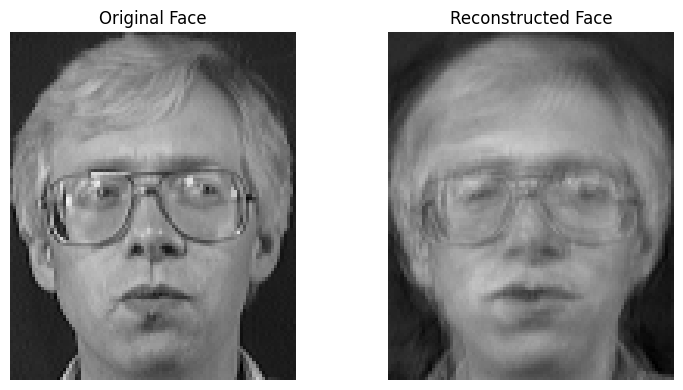

Reduced training representation: (320, 98)
Reduced testing representation: (80, 98)
Test reconstruction MSE: 329.98300776168344


In [34]:
# Keep only the components required for 90% variance
selected_components = components_svd[:k]

# Project training and test images into PCA space
X_train_pca = X_centered @ selected_components.T
X_test_centered = X_test_float - mean_face
X_test_pca = X_test_centered @ selected_components.T

# Reconstruct test images from their reduced representation
X_test_reconstructed = (
    X_test_pca @ selected_components
) + mean_face

# Display an original image and its reconstruction
sample_index = 0

original_face = X_test_float[sample_index].reshape(
    image_height, image_width
)
reconstructed_face = X_test_reconstructed[sample_index].reshape(
    image_height, image_width
)

plt.figure(figsize=(8, 4))

plt.subplot(1, 2, 1)
plt.imshow(original_face, cmap="gray", vmin=0, vmax=255)
plt.title("Original Face")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(
    np.clip(reconstructed_face, 0, 255),
    cmap="gray", vmin=0, vmax=255
)
plt.title("Reconstructed Face")
plt.axis("off")

plt.tight_layout()
plt.show()

# Calculate reconstruction quality
mse = np.mean((X_test_float - X_test_reconstructed) ** 2)

print("Reduced training representation:", X_train_pca.shape)
print("Reduced testing representation:", X_test_pca.shape)
print("Test reconstruction MSE:", mse)

In [35]:
# Original image storage: 8 bits per pixel
original_bytes_per_image = X_train.shape[1] * np.dtype(np.uint8).itemsize

# Reduced representation: store k coefficients as float32
compressed_bytes_per_image = k * np.dtype(np.float32).itemsize

# Storage needed for the PCA model itself
model_bytes = (
    mean_face.astype(np.float32).nbytes
    + selected_components.astype(np.float32).nbytes
)

reduction_percent = (
    1 - compressed_bytes_per_image / original_bytes_per_image
) * 100

print("Original bytes per image:", original_bytes_per_image)
print("Reduced coefficients bytes per image:", compressed_bytes_per_image)
print("PCA model storage in bytes:", model_bytes)
print("Per-image storage reduction:", round(reduction_percent, 2), "%")

# Compare total storage for the training dataset
original_total = len(X_train) * original_bytes_per_image
compressed_total = (
    len(X_train) * compressed_bytes_per_image + model_bytes
)

print("Original training dataset bytes:", original_total)
print("Reduced data plus PCA model bytes:", compressed_total)
print("Total storage reduction:",
      round((1 - compressed_total / original_total) * 100, 2), "%")

Original bytes per image: 10304
Reduced coefficients bytes per image: 392
PCA model storage in bytes: 4080384
Per-image storage reduction: 96.2 %
Original training dataset bytes: 3297280
Reduced data plus PCA model bytes: 4205824
Total storage reduction: -27.55 %


## Part C - Recognition in PCA Space 


In [36]:
import numpy as np
import matplotlib.pyplot as plt

print("Training images:", X_train.shape)
print("Testing images:", X_test.shape)
print("PCA components:", k)

Training images: (320, 10304)
Testing images: (80, 10304)
PCA components: 98


In [37]:
# Calculate Euclidean distances between test and training PCA features
distances_pca = np.sqrt(
    np.sum(
        (X_test_pca[:, np.newaxis, :] -
         X_train_pca[np.newaxis, :, :]) ** 2,
        axis=2
    )
)

# Index of the closest training face for each test image
closest_pca = np.argmin(distances_pca, axis=1)

# Predicted subject labels
y_pred_pca = y_train[closest_pca]

# Recognition accuracy
accuracy_pca = np.mean(y_pred_pca == y_test)

print("PCA recognition accuracy:", round(accuracy_pca * 100, 2), "%")

PCA recognition accuracy: 95.0 %


In [38]:
# Convert raw pixel values to float
X_train_raw = X_train.astype(float)
X_test_raw = X_test.astype(float)

# Euclidean distances in raw pixel space
distances_raw = np.sqrt(
    np.sum(
        (X_test_raw[:, np.newaxis, :] -
         X_train_raw[np.newaxis, :, :]) ** 2,
        axis=2
    )
)

# Find closest raw-pixel training faces
closest_raw = np.argmin(distances_raw, axis=1)
y_pred_raw = y_train[closest_raw]

# Recognition accuracy
accuracy_raw = np.mean(y_pred_raw == y_test)

print("Raw pixel recognition accuracy:",
      round(accuracy_raw * 100, 2), "%")

print("PCA recognition accuracy:",
      round(accuracy_pca * 100, 2), "%")

Raw pixel recognition accuracy: 95.0 %
PCA recognition accuracy: 95.0 %


Raw Pixels : 95.0 %
PCA Features : 95.0 %


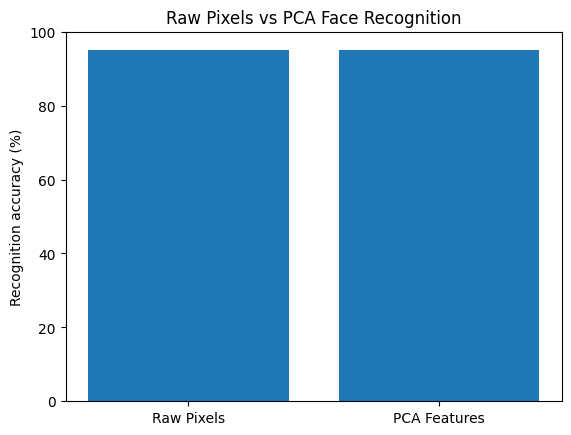

In [39]:
methods = ["Raw Pixels", "PCA Features"]
accuracies = [accuracy_raw * 100, accuracy_pca * 100]

for method, accuracy in zip(methods, accuracies):
    print(method, ":", round(accuracy, 2), "%")

plt.bar(methods, accuracies)
plt.ylabel("Recognition accuracy (%)")
plt.title("Raw Pixels vs PCA Face Recognition")
plt.ylim(0, 100)
plt.show()

Correct matches: 76
Incorrect matches: 4


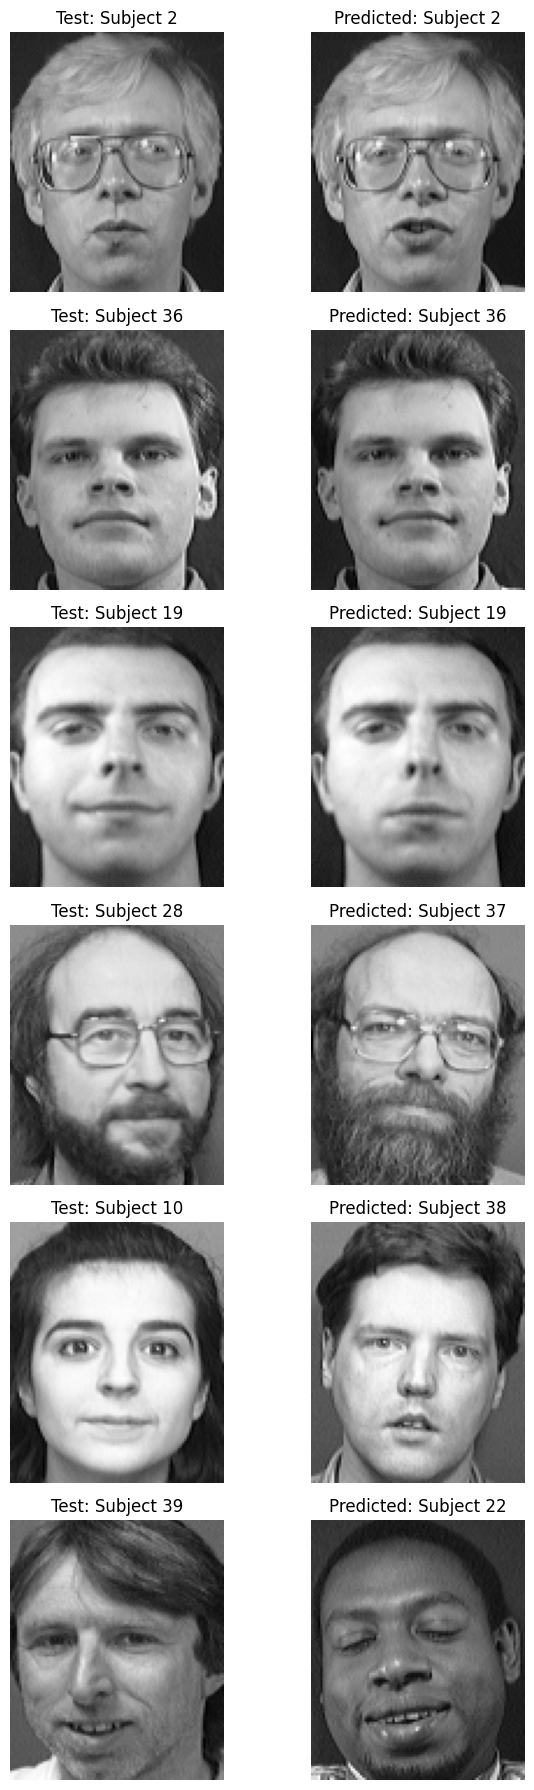

In [40]:
correct_indices = np.where(y_pred_pca == y_test)[0]
incorrect_indices = np.where(y_pred_pca != y_test)[0]

print("Correct matches:", len(correct_indices))
print("Incorrect matches:", len(incorrect_indices))

selected_indices = list(correct_indices[:3]) + list(incorrect_indices[:3])

if len(selected_indices) == 0:
    print("No test images available.")
else:
    fig, axes = plt.subplots(
        len(selected_indices), 2,
        figsize=(7, 3 * len(selected_indices))
    )

    if len(selected_indices) == 1:
        axes = np.array([axes])

    for row, test_index in enumerate(selected_indices):
        train_index = closest_pca[test_index]

        axes[row, 0].imshow(
            X_test[test_index].reshape(image_height, image_width),
            cmap="gray"
        )
        axes[row, 0].set_title(
            "Test: Subject " + str(y_test[test_index])
        )
        axes[row, 0].axis("off")

        axes[row, 1].imshow(
            X_train[train_index].reshape(image_height, image_width),
            cmap="gray"
        )
        axes[row, 1].set_title(
            "Predicted: Subject " + str(y_pred_pca[test_index])
        )
        axes[row, 1].axis("off")

    plt.tight_layout()
    plt.show()

In [41]:
print("PCA Face Recognition Report")
print("----------------------------")

for i in range(min(10, len(y_test))):
    status = "Correct" if y_pred_pca[i] == y_test[i] else "Incorrect"

    print(
        "Test image:", i,
        "| Actual subject:", y_test[i],
        "| Predicted subject:", y_pred_pca[i],
        "| Nearest distance:", round(distances_pca[i, closest_pca[i]], 2),
        "|", status
    )

print("\nFinal Results")
print("Raw pixel accuracy:", round(accuracy_raw * 100, 2), "%")
print("PCA accuracy:", round(accuracy_pca * 100, 2), "%")

PCA Face Recognition Report
----------------------------
Test image: 0 | Actual subject: 2 | Predicted subject: 2 | Nearest distance: 986.68 | Correct
Test image: 1 | Actual subject: 36 | Predicted subject: 36 | Nearest distance: 1625.86 | Correct
Test image: 2 | Actual subject: 19 | Predicted subject: 19 | Nearest distance: 799.34 | Correct
Test image: 3 | Actual subject: 17 | Predicted subject: 17 | Nearest distance: 1332.7 | Correct
Test image: 4 | Actual subject: 40 | Predicted subject: 40 | Nearest distance: 2018.37 | Correct
Test image: 5 | Actual subject: 24 | Predicted subject: 24 | Nearest distance: 2093.5 | Correct
Test image: 6 | Actual subject: 33 | Predicted subject: 33 | Nearest distance: 1552.25 | Correct
Test image: 7 | Actual subject: 20 | Predicted subject: 20 | Nearest distance: 1976.69 | Correct
Test image: 8 | Actual subject: 4 | Predicted subject: 4 | Nearest distance: 2713.38 | Correct
Test image: 9 | Actual subject: 35 | Predicted subject: 35 | Nearest distance:

## Part D - Traditional Machine Learning 


In [42]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score

print("Training images:", X_train.shape)
print("Testing images:", X_test.shape)
print("Components for 90% variance:", k)

Training images: (320, 10304)
Testing images: (80, 10304)
Components for 90% variance: 98


In [43]:
component_options = [10, 20, 30, 50, k]

component_options = sorted(set(
    n for n in component_options
    if n <= len(components_svd)
))

print("Component counts to test:", component_options)

for n in component_options:
    print(
        n, "components preserve",
        round(np.sum(variance_svd[:n]) * 100, 2),
        "% variance"
    )

Component counts to test: [10, 20, 30, 50, 98]
10 components preserve 60.14 % variance
20 components preserve 70.49 % variance
30 components preserve 76.0 % variance
50 components preserve 82.48 % variance
98 components preserve 90.06 % variance


In [44]:
results = []
trained_models = {}

for n in component_options:

    # Generate PCA features using the selected components
    components = components_svd[:n]

    train_features = X_centered @ components.T
    test_features = X_test_centered @ components.T

    models = {
        "KNN": (
            KNeighborsClassifier(),
            {"n_neighbors": [1, 3, 5]}
        ),
        "Logistic Regression": (
            LogisticRegression(max_iter=3000),
            {"C": [0.1, 1, 10]}
        ),
        "SVM": (
            SVC(),
            {"C": [1, 10], "kernel": ["linear", "rbf"]}
        )
    }

    for name, (model, parameters) in models.items():

        search = GridSearchCV(
            model,
            parameters,
            cv=3,
            scoring="accuracy",
            n_jobs=-1
        )

        search.fit(train_features, y_train)

        predictions = search.predict(test_features)
        test_accuracy = accuracy_score(y_test, predictions)

        results.append({
            "Components": n,
            "Model": name,
            "CV Accuracy": search.best_score_,
            "Test Accuracy": test_accuracy,
            "Best Parameters": search.best_params_
        })

        trained_models[(n, name)] = search.best_estimator_

        print(
            "Components:", n,
            "| Model:", name,
            "| CV:", round(search.best_score_ * 100, 2), "%",
            "| Test:", round(test_accuracy * 100, 2), "%",
            "| Parameters:", search.best_params_
        )

Components: 10 | Model: KNN | CV: 91.25 % | Test: 95.0 % | Parameters: {'n_neighbors': 1}
Components: 10 | Model: Logistic Regression | CV: 91.24 % | Test: 86.25 % | Parameters: {'C': 10}
Components: 10 | Model: SVM | CV: 93.44 % | Test: 95.0 % | Parameters: {'C': 1, 'kernel': 'linear'}
Components: 20 | Model: KNN | CV: 93.75 % | Test: 95.0 % | Parameters: {'n_neighbors': 1}
Components: 20 | Model: Logistic Regression | CV: 97.19 % | Test: 95.0 % | Parameters: {'C': 0.1}
Components: 20 | Model: SVM | CV: 95.62 % | Test: 95.0 % | Parameters: {'C': 1, 'kernel': 'linear'}
Components: 30 | Model: KNN | CV: 95.63 % | Test: 95.0 % | Parameters: {'n_neighbors': 1}
Components: 30 | Model: Logistic Regression | CV: 98.12 % | Test: 95.0 % | Parameters: {'C': 0.1}
Components: 30 | Model: SVM | CV: 97.5 % | Test: 95.0 % | Parameters: {'C': 10, 'kernel': 'rbf'}
Components: 50 | Model: KNN | CV: 96.56 % | Test: 96.25 % | Parameters: {'n_neighbors': 1}
Components: 50 | Model: Logistic Regression | CV

In [45]:
import pandas as pd
results_df = pd.DataFrame(results)
results_df = results_df.sort_values(
    by="CV Accuracy",
    ascending=False
)

print(results_df.to_string(index=False))

 Components               Model  CV Accuracy  Test Accuracy              Best Parameters
         30 Logistic Regression     0.981250         0.9500                   {'C': 0.1}
         50 Logistic Regression     0.978134         0.9875                   {'C': 0.1}
         50                 SVM     0.978105         0.9750   {'C': 10, 'kernel': 'rbf'}
         98                 SVM     0.978105         0.9625   {'C': 10, 'kernel': 'rbf'}
         30                 SVM     0.974990         0.9500   {'C': 10, 'kernel': 'rbf'}
         20 Logistic Regression     0.971904         0.9500                   {'C': 0.1}
         98 Logistic Regression     0.971874         0.9875                   {'C': 0.1}
         50                 KNN     0.965615         0.9625           {'n_neighbors': 1}
         30                 KNN     0.956269         0.9500           {'n_neighbors': 1}
         20                 SVM     0.956239         0.9500 {'C': 1, 'kernel': 'linear'}
         98          

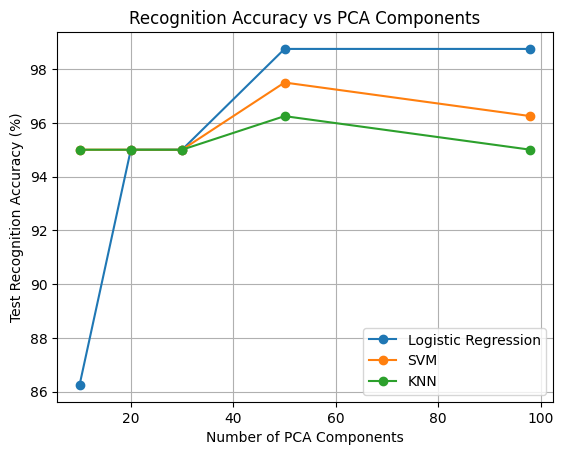

In [46]:
for name in results_df["Model"].unique():

    model_results = results_df[
        results_df["Model"] == name
    ].sort_values("Components")

    plt.plot(
        model_results["Components"],
        model_results["Test Accuracy"] * 100,
        marker="o",
        label=name
    )

plt.xlabel("Number of PCA Components")
plt.ylabel("Test Recognition Accuracy (%)")
plt.title("Recognition Accuracy vs PCA Components")
plt.legend()
plt.grid(True)
plt.show()